# 03 · Harm audit of the "naive" recommender

The SVD model from notebook 02 is accurate. Now we ask a different question: **who is it recommending what to?**

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from src.recsys import *

plt.rcParams["figure.figsize"] = (8, 4.5)
TEAL, CORAL, GREY = "#1f6f8b", "#e07a5f", "#9aa5ab"

In [2]:
import json
from surprise import SVD
from surprise.model_selection import train_test_split

customers, catalogue, engagement = load_tables()
flags = get_flags(make_database(customers, catalogue, engagement))
best_params = json.load(open("../results/model_selection.json"))["best_params"]

data = to_surprise(engagement)
trainset, testset = train_test_split(data, test_size=0.2, random_state=42)
svd = SVD(**best_params).fit(trainset)
ranked = rank_unseen(svd, trainset, catalogue["item_id"].tolist())
naive = top_n(ranked)

## 1. What does the naive top-5 contain, for flagged vs non-flagged customers?

In [3]:
cat = catalogue.set_index("item_id")
rows = [{"customer_id": u, "item_id": i} for u, its in naive.items() for i in its]
recs = (pd.DataFrame(rows).merge(catalogue, on="item_id")
        .merge(flags[["customer_id", "financial_difficulty_flag"]], on="customer_id"))
recs["category"] = np.select(
    [recs["item_id"].isin(["O12", "O13"]), recs["item_type"].eq("credit"),
     recs["item_type"].eq("investment") & recs["risk_level"].ne("none"), recs["supportive"].eq(1)],
    ["Gambling offer", "Credit", "Risky investment", "Supportive feature"], "Other offer / feature")
mix = (pd.crosstab(recs["financial_difficulty_flag"], recs["category"], normalize="index") * 100).round(1)
mix.index = ["Not flagged", "In financial difficulty"]
mix

category,Credit,Gambling offer,Other offer / feature,Risky investment,Supportive feature
Not flagged,18.0,1.5,39.8,10.7,29.8
In financial difficulty,20.5,5.7,44.3,11.0,18.5


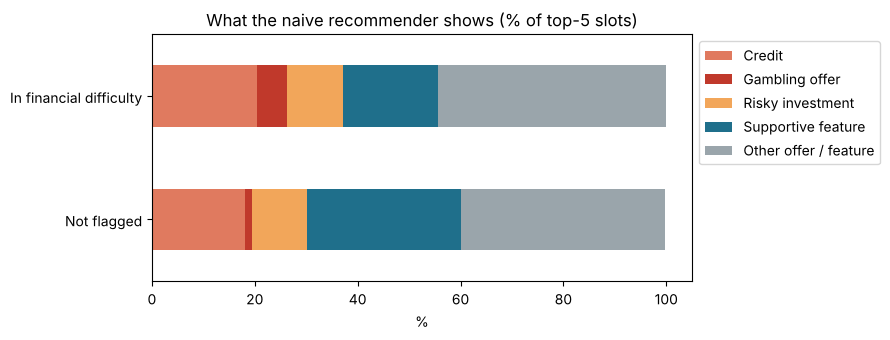

In [4]:
order = ["Credit", "Gambling offer", "Risky investment", "Supportive feature", "Other offer / feature"]
mix[order].plot.barh(stacked=True, color=[CORAL, "#c0392b", "#f2a65a", TEAL, GREY], figsize=(9, 3.5))
plt.title("What the naive recommender shows (% of top-5 slots)"); plt.xlabel("%")
plt.legend(bbox_to_anchor=(1, 1)); plt.tight_layout()
plt.savefig("../images/naive_mix.png", dpi=120, bbox_inches="tight"); plt.show()

## 2. Harm metrics

In [5]:
naive_harm = harm_report(naive, catalogue, flags)
pd.Series(naive_harm).round(1).to_frame("naive recommender")

,naive recommender
% of flagged customers shown a restricted item,92.7
% of flagged customers' slots that are restricted,37.2
% of flagged customers shown a supportive feature,43.8
% of all customers shown credit/risky investment without passing affordability,54.6


## 3. Which products are pushed hardest to flagged customers?

In [6]:
flagged_recs = recs[recs["financial_difficulty_flag"] == 1]
(flagged_recs["item_name"].value_counts(normalize=True).head(10) * 100).round(1).to_frame("% of flagged customers' slots")

,% of flagged customers' slots
item_name,
Credit card,9.2
Cashback: electronics,9.1
Cashback: supermarket,7.6
"Buy now, pay later",7.6
Cashback: restaurants,6.4
Crypto trading,5.6
Stocks & shares ISA,5.4
Cashback: fashion,5.2
Salary sorter,5.0


In [7]:
json.dump({k: float(v) for k, v in naive_harm.items()}, open("../results/naive_harm.json", "w"), indent=2)

## Findings

The model did exactly what it was trained to do: it learned that customers in financial difficulty engage with high-cost credit and gambling offers, so it shows them **more** of both. Most flagged customers get at least one restricted item in their top 5.

Nothing here is a bug. **The objective (engagement) is the problem.** That's the core lesson: an accurate model can still produce outcomes a firm cannot defend under the Consumer Duty. Notebook 04 adds guardrails.